# ***Demand Forecasting***

## **Data and Libraries Import**

`Importing libraries`

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import os
import pickle
from pathlib import Path
from dotenv import load_dotenv,find_dotenv

from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *

from statsforecast import StatsForecast
from statsforecast.models import Naive, AutoARIMA, SeasonalNaive, AutoTheta, AutoETS

from sqlalchemy import create_engine, text


import warnings
warnings.filterwarnings('ignore')

`Initializing the env-variables so that no one sees the actual credentials
`

In [4]:
env_path = Path.cwd()/"github_repo_cloned"/"distribution_hub_optimizer"/".env"
load_dotenv(env_path)

HOST = os.getenv("DB_HOST")
USER = os.getenv("DB_USER")
PASSWORD = os.getenv("DB_PASSWORD")
PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
OUTPUT_DIR = Path(os.getenv("OUTPUT_DIR", Path.cwd()/"outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

`Creating the engine to connect with the database`

In [5]:
engine = create_engine(f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}")


def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

In [6]:
query = "select * from forecasting_data"

data = sql(query=query,engine=engine)

In [7]:
data.head()

,state,date,fy,bill_volume,bill_amount,avg_bill_3m,avg_amount_3m,avg_amount_12m
0,andaman and nicobar,2019-04,2019-20,8659.0,229.59,8659.00,229.59,229.59
1,andaman and nicobar,2019-05,2019-20,8731.0,276.99,8695.00,253.29,253.29
2,andaman and nicobar,2019-06,2019-20,7320.0,190.68,8236.67,232.42,232.42
3,andaman and nicobar,2019-07,2019-20,8619.0,217.12,8223.33,228.26,228.60
4,andaman and nicobar,2019-08,2019-20,9119.0,228.28,8352.67,212.03,228.53


## **Initial Data Check**

`Structure and Types`

In [8]:
data.nunique().reset_index(name = 'unique_counts')

,index,unique_counts
0,state,35
1,date,84
2,fy,7
3,bill_volume,2931
4,bill_amount,2940
5,avg_bill_3m,2939
6,avg_amount_3m,2938
7,avg_amount_12m,2932


In [9]:
print(f"Row Counts: {data.shape[0]}")
print(f"Columns Counts: {data.shape[1]}")

Row Counts: 2940
Columns Counts: 8


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2940 entries, 0 to 2939
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   state           2940 non-null   object 
 1   date            2940 non-null   object 
 2   fy              2940 non-null   object 
 3   bill_volume     2940 non-null   float64
 4   bill_amount     2940 non-null   float64
 5   avg_bill_3m     2940 non-null   float64
 6   avg_amount_3m   2940 non-null   float64
 7   avg_amount_12m  2940 non-null   float64
dtypes: float64(5), object(3)
memory usage: 183.9+ KB


In [11]:
data['date']=pd.to_datetime(data['date'])

In [12]:
data.tail()

,state,date,fy,bill_volume,bill_amount,avg_bill_3m,avg_amount_3m,avg_amount_12m
2935,west bengal,2025-11-01,2025-26,7545925.0,187031.61,7424885.33,181184.99,182355.89
2936,west bengal,2025-12-01,2025-26,8228781.0,201065.10,7641221.00,185586.96,184358.72
2937,west bengal,2026-01-01,2025-26,8171882.0,199359.02,7982196.00,195818.58,185482.32
2938,west bengal,2026-02-01,2025-26,8179353.0,201478.89,8193338.67,200634.34,187809.87
2939,west bengal,2026-03-01,2025-26,8277353.0,222011.33,8209529.33,207616.41,189568.59


In [13]:
# Renaming columns for easy usage
rename_dict = {
    'bill_volume':'volume',
    'bill_amount':'amount'
}

data.rename(rename_dict,axis=1, inplace=True)

In [14]:
data.head()

,state,date,fy,volume,amount,avg_bill_3m,avg_amount_3m,avg_amount_12m
0,andaman and nicobar,2019-04-01,2019-20,8659.0,229.59,8659.00,229.59,229.59
1,andaman and nicobar,2019-05-01,2019-20,8731.0,276.99,8695.00,253.29,253.29
2,andaman and nicobar,2019-06-01,2019-20,7320.0,190.68,8236.67,232.42,232.42
3,andaman and nicobar,2019-07-01,2019-20,8619.0,217.12,8223.33,228.26,228.60
4,andaman and nicobar,2019-08-01,2019-20,9119.0,228.28,8352.67,212.03,228.53


In [15]:
data.isnull().sum().reset_index(name = 'null_values')

,index,null_values
0,state,0
1,date,0
2,fy,0
3,volume,0
4,amount,0
5,avg_bill_3m,0
6,avg_amount_3m,0
7,avg_amount_12m,0


`Integrity`

In [16]:
cols_needed = ['date','volume','amount']
desc = data[cols_needed].describe().round(2).reset_index()
desc

,index,date,volume,amount
0,count,2940,2940.00,2940.00
1,mean,2022-09-15 22:00:00,3150025.87,89564.97
2,min,2019-04-01 00:00:00,78.00,1.43
3,25%,2020-12-24 06:00:00,114238.75,4167.16
4,50%,2022-09-16 00:00:00,1192246.50,39223.04
5,75%,2024-06-08 12:00:00,4245790.25,127490.09
6,max,2026-03-01 00:00:00,27217002.00,851046.04
7,std,NaN,4425408.65,123308.99


`Checking if there is any duplicate state and date combo`

In [17]:
data.groupby(['state','date']).size().reset_index(name = 'cnt').query('cnt>1')

,state,date,cnt


`Value Validity`

In [18]:
data = data.sort_values(by=['state','date'])
data['amt_per_bill'] = (data['amount']/data['volume'])*100
data['change_pct'] = data.groupby('state')['amt_per_bill'].pct_change()*100
data.head()

,state,date,fy,volume,amount,avg_bill_3m,avg_amount_3m,avg_amount_12m,amt_per_bill,change_pct
0,andaman and nicobar,2019-04-01,2019-20,8659.0,229.59,8659.00,229.59,229.59,2.651461,NaN
1,andaman and nicobar,2019-05-01,2019-20,8731.0,276.99,8695.00,253.29,253.29,3.172489,19.650598
2,andaman and nicobar,2019-06-01,2019-20,7320.0,190.68,8236.67,232.42,232.42,2.604918,-17.890396
3,andaman and nicobar,2019-07-01,2019-20,8619.0,217.12,8223.33,228.26,228.60,2.519086,-3.295009
4,andaman and nicobar,2019-08-01,2019-20,9119.0,228.28,8352.67,212.03,228.53,2.503345,-0.624873


`Checking for anomaly in change percentage`

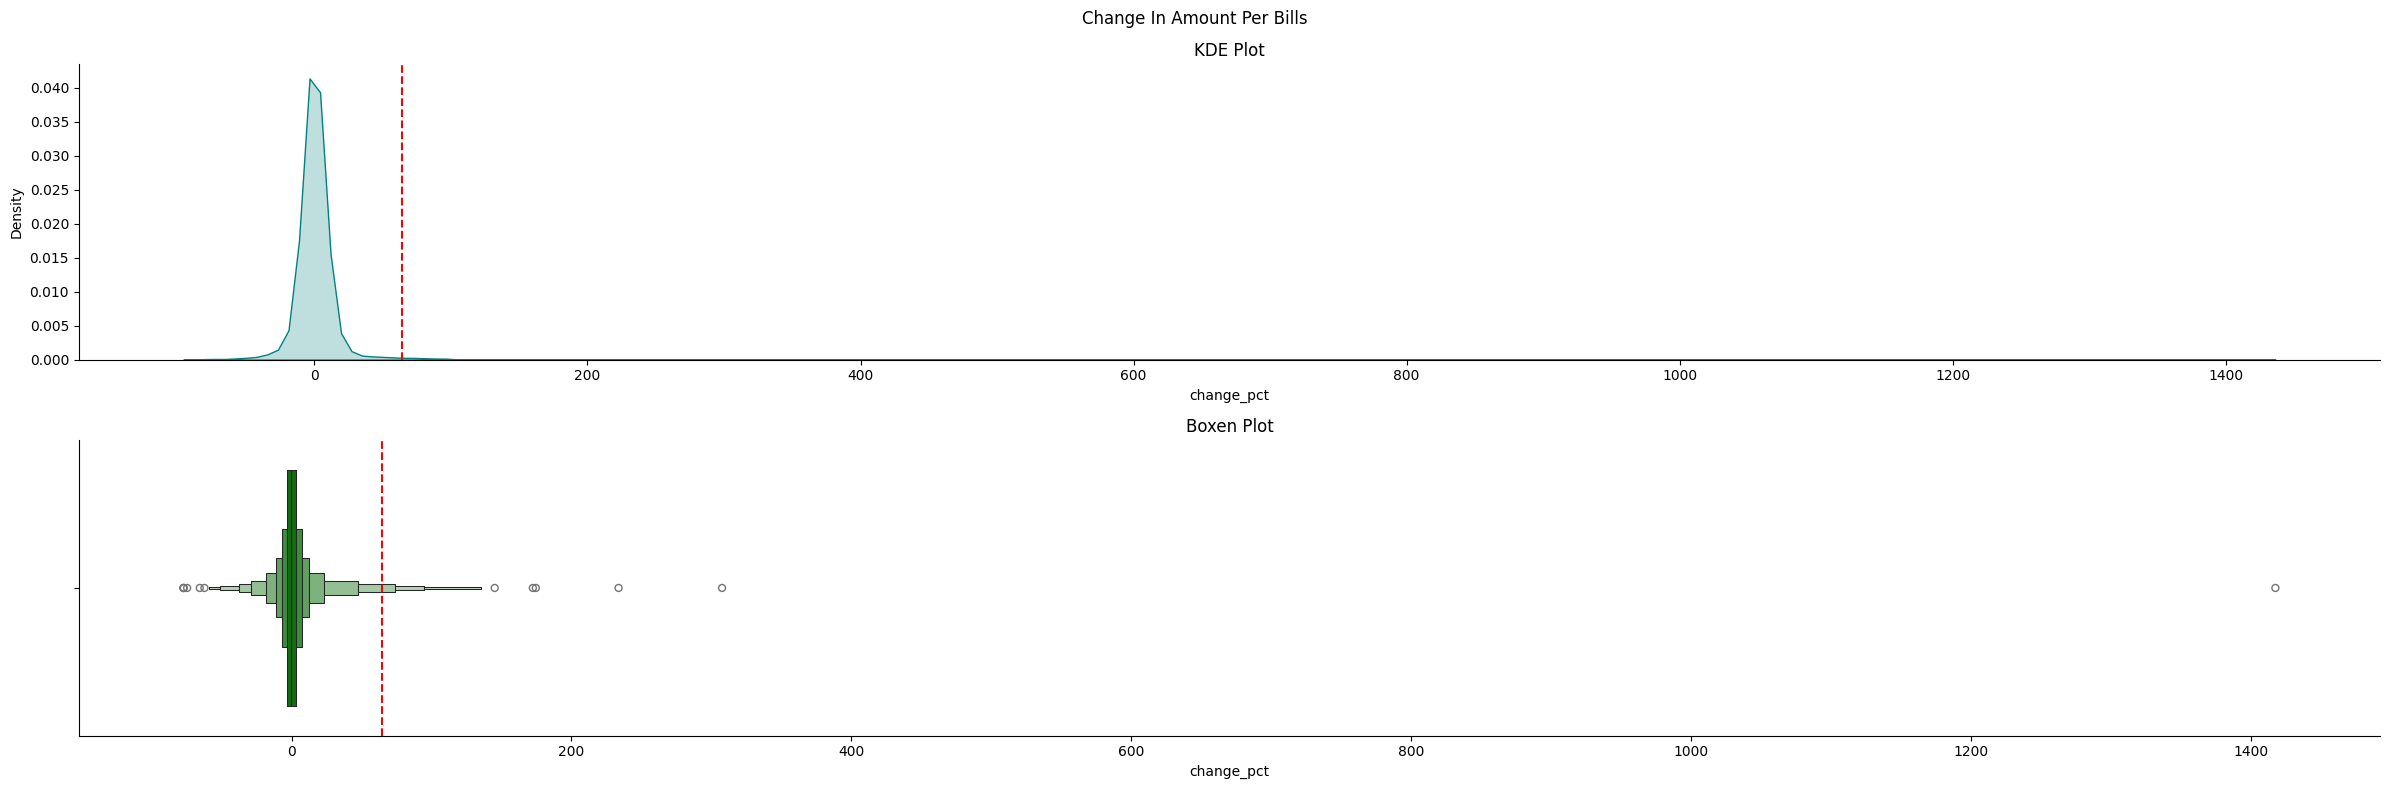

In [19]:
plt.figure(figsize=(24,8))
plt.subplot(2,1,1)
sns.kdeplot(x = 'change_pct',data=data,color='teal',fill=True)
plt.axvline(data['change_pct'].quantile(.99),color='red',linestyle='--')
plt.title("KDE Plot")
plt.subplot(2,1,2)
sns.boxenplot(x = 'change_pct',data=data,color='green')
plt.axvline(data['change_pct'].quantile(.99),color='red',linestyle='--')
plt.title("Boxen Plot")
plt.suptitle("Change In Amount Per Bills")
sns.despine()
plt.tight_layout()
plt.show()

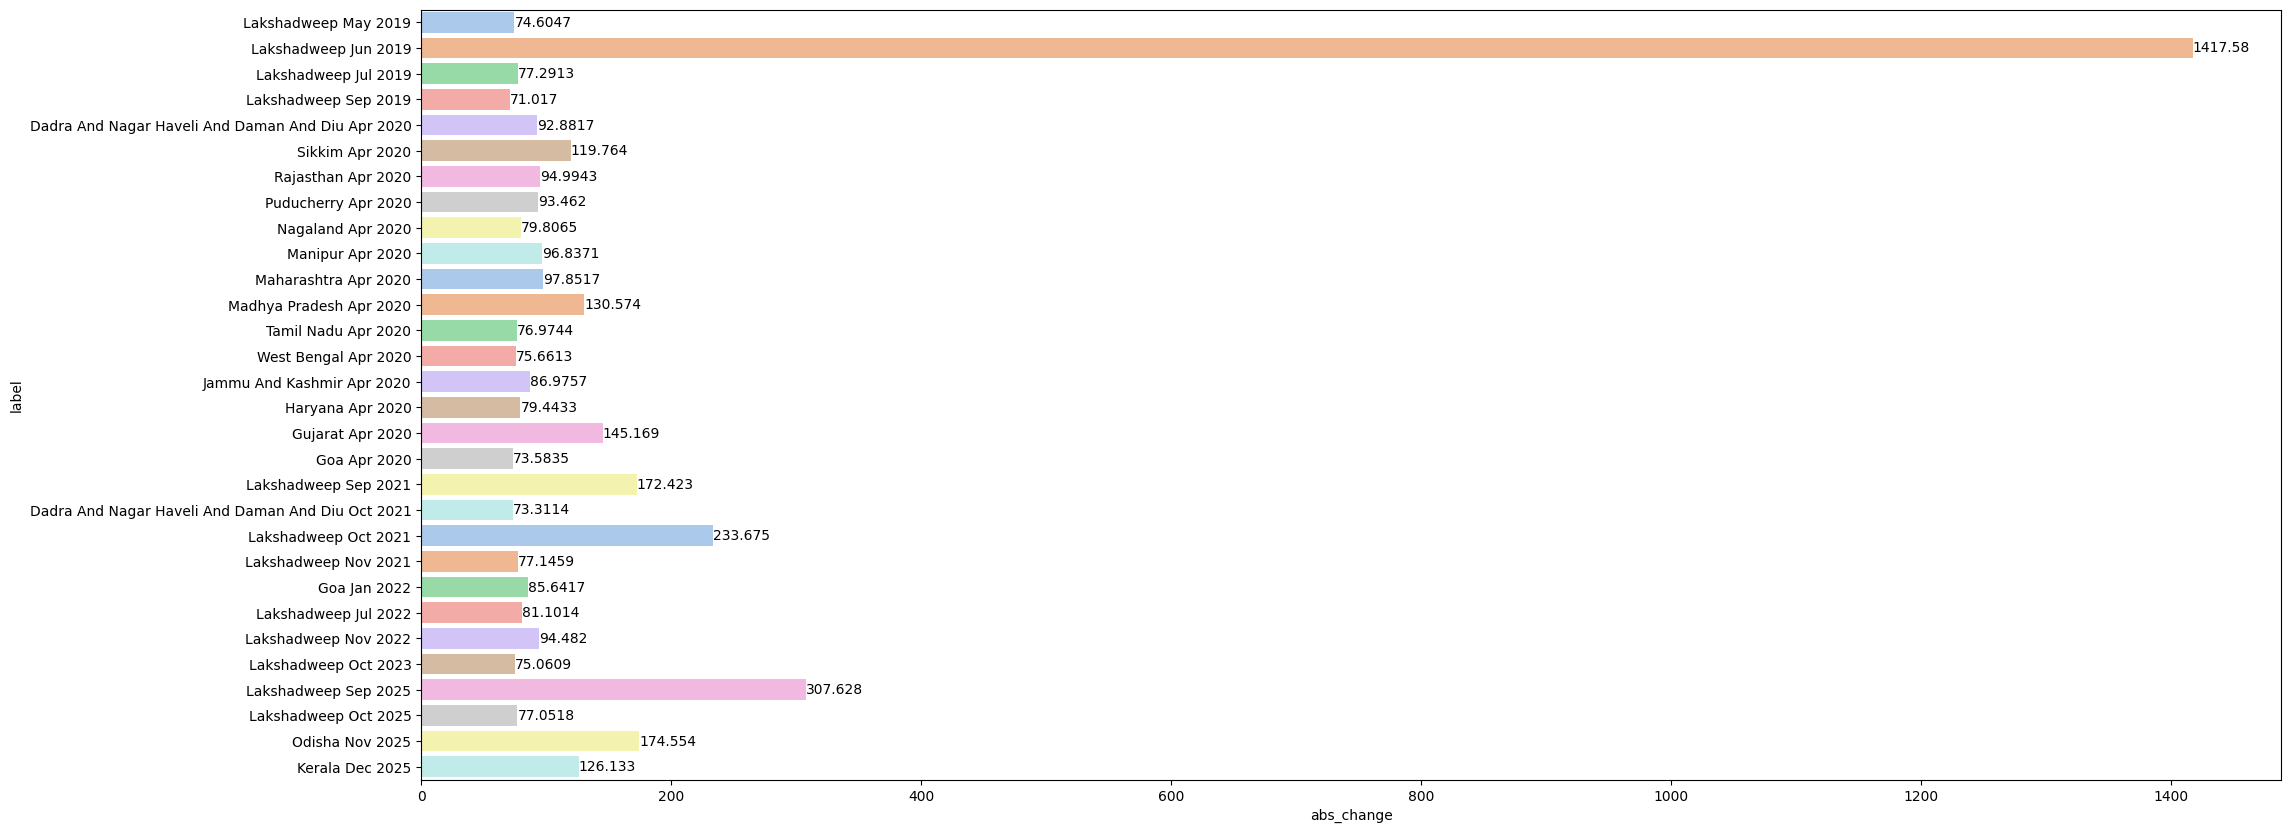

In [20]:
data['abs_change']= data['change_pct'].abs()
anomaly_changes = data[data['abs_change']>data['abs_change'].quantile(.99)].sort_values(by='date',ascending=True)
anomaly_changes['label'] = anomaly_changes['state'].str.title()+ " " + anomaly_changes['date'].dt.strftime('%b %Y')
plt.figure(figsize=(24,10))
ax = sns.barplot(x='abs_change',y='label',data=anomaly_changes,palette='pastel')
for container in ax.containers:
    ax.bar_label(container=container)
plt.show()

In [21]:
anomaly_changes['state'].value_counts().reset_index(name = 'count')

,state,count
0,lakshadweep,12
1,dadra and nagar haveli and daman and diu,2
2,goa,2
3,rajasthan,1
4,sikkim,1
5,nagaland,1
6,manipur,1
7,maharashtra,1
8,puducherry,1
9,madhya pradesh,1


---
Lakshadeep have some problematic values, which falls under outliers

---

In [ ]:
data.head()

,state,date,fy,volume,amount,avg_bill_3m,avg_amount_3m,avg_amount_12m,amt_per_bill,change_pct,abs_change
0,andaman and nicobar,2019-04-01,2019-20,8659.0,229.59,8659.00,229.59,229.59,2.651461,NaN,NaN
1,andaman and nicobar,2019-05-01,2019-20,8731.0,276.99,8695.00,253.29,253.29,3.172489,19.650598,19.650598
2,andaman and nicobar,2019-06-01,2019-20,7320.0,190.68,8236.67,232.42,232.42,2.604918,-17.890396,17.890396
3,andaman and nicobar,2019-07-01,2019-20,8619.0,217.12,8223.33,228.26,228.60,2.519086,-3.295009,3.295009
4,andaman and nicobar,2019-08-01,2019-20,9119.0,228.28,8352.67,212.03,228.53,2.503345,-0.624873,0.624873


## EDA

In [25]:
def plot_bill_trend(column, title="", ylabel="Bill Volume", filename=None):
    plt.figure(figsize=(25,8))
    ax = sns.lineplot(x='date', y=column, data=data, color='#1B7A72')
    ax.set_title(title, weight='bold', fontsize=20)
    plt.xlabel("Date", fontsize=10, weight='bold')
    plt.ylabel(ylabel, fontsize=15, weight='bold')

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
    ax.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
    ax.tick_params(axis='x', which='major', labelsize=11, pad=20)
    ax.tick_params(axis='x', which='minor', labelsize=8, colors='black')

    lockdown_start = pd.Timestamp('2020-03-01')
    lockdown_end = pd.Timestamp('2020-06-30')
    ax.axvspan(lockdown_start, lockdown_end, color='red', alpha=0.12, zorder=0)
    ax.text(lockdown_start + (lockdown_end - lockdown_start)/2, ax.get_ylim()[1]*0.95,
            'COVID-19\nLockdown', ha='center', va='top', fontsize=9, color='darkred', weight='bold')

    sns.despine(left=True, bottom=True)
    ax.grid(axis='y', alpha=0.3)
    ax.grid(axis='x', visible=False)
    plt.tight_layout()

    filename = filename or f"{column}_trend.png"
    plt.savefig(OUTPUT_DIR/filename, dpi=150, bbox_inches='tight')
    plt.show()

`Visualizing the trend for future forecasting, using 3 months rolling average`

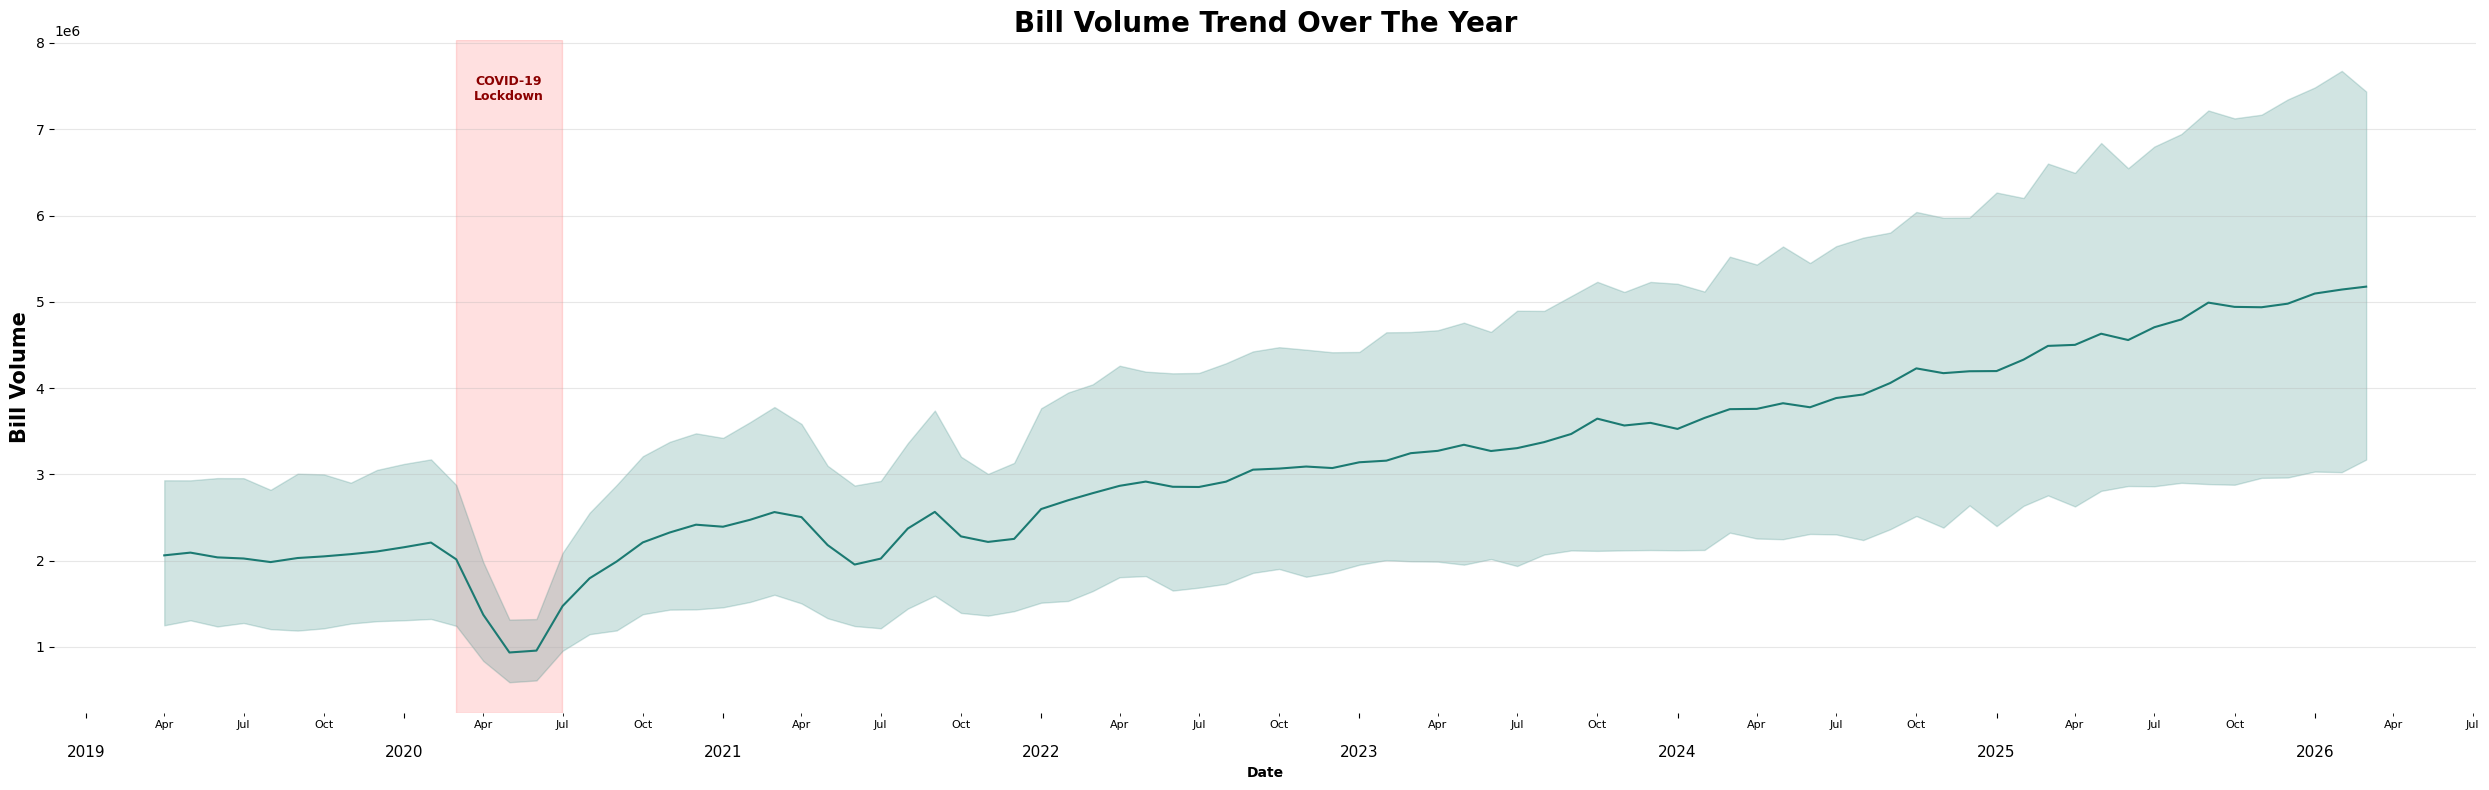

In [26]:
plot_bill_trend('avg_bill_3m',title="Bill Volume Trend Over The Year",ylabel="Bill Volume",filename="bill_volume_trend.png")

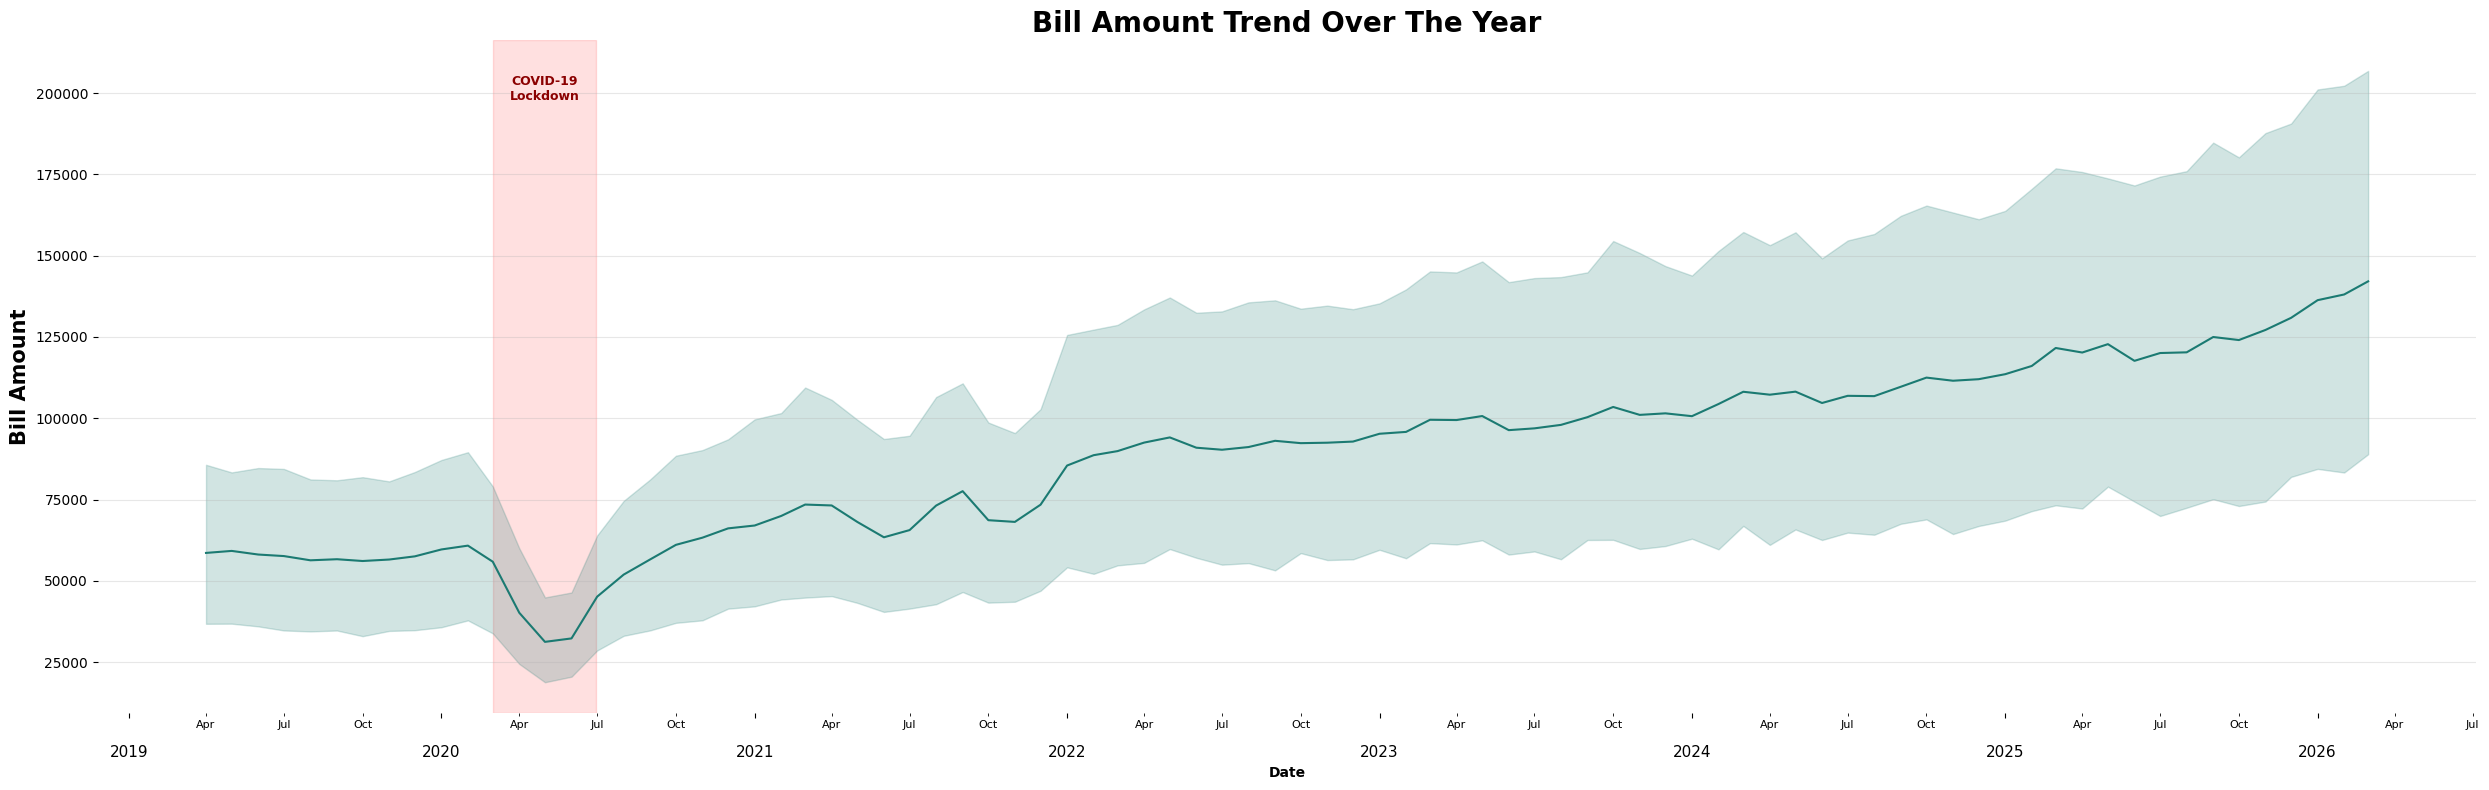

In [27]:
plot_bill_trend('avg_amount_3m',title="Bill Amount Trend Over The Year",ylabel="Bill Amount",filename="bill_amount_trend.png")

`Visualizing raw`

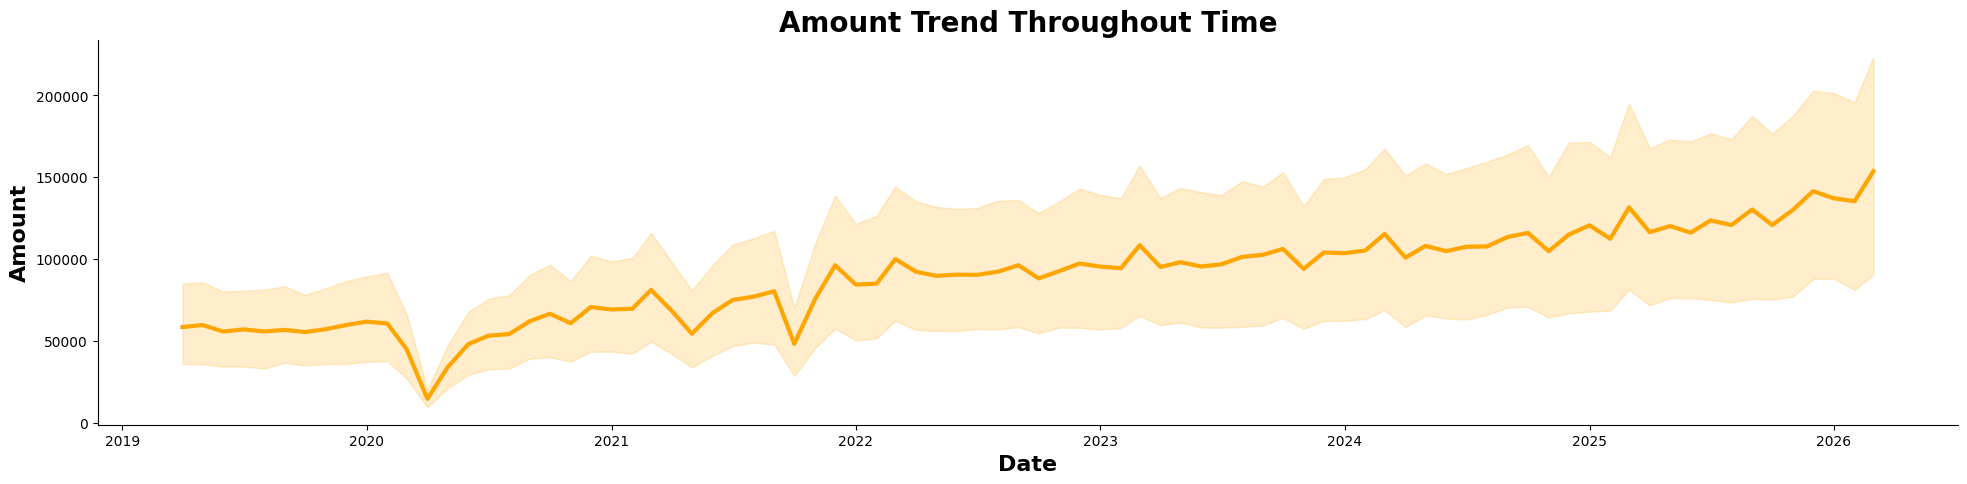

In [28]:
plt.figure(figsize=(24,5))
sns.lineplot(x = 'date',y='amount',data=data,linewidth=3,color='orange')
plt.title('Amount Trend Throughout Time',fontsize= 20,weight = 'bold')
plt.xlabel("Date",fontsize=16,weight = 'bold')
plt.ylabel("Amount",fontsize=16,weight = 'bold')
sns.despine()
plt.show()

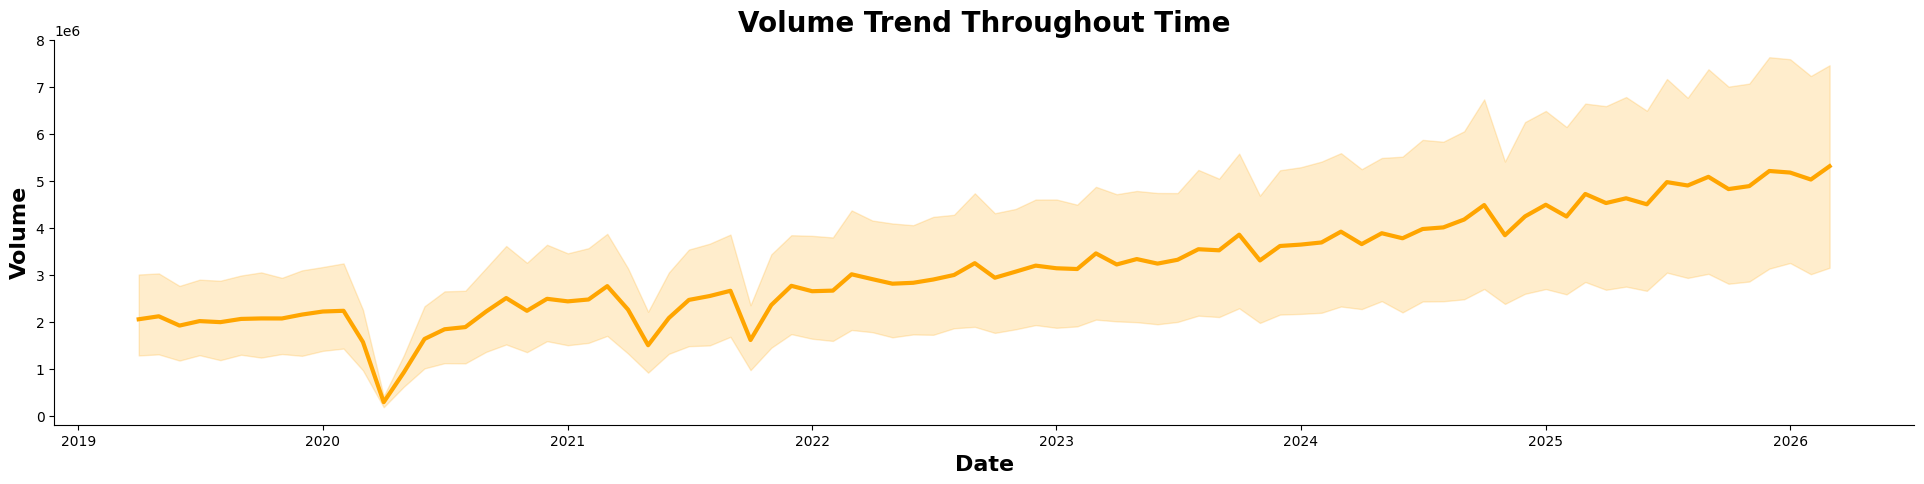

In [29]:
plt.figure(figsize=(24,5))
sns.lineplot(x = 'date',y='volume',data=data,linewidth=3,color='orange')
plt.title('Volume Trend Throughout Time',fontsize= 20,weight = 'bold')
plt.xlabel("Date",fontsize=16,weight = 'bold')
plt.ylabel("Volume",fontsize=16,weight = 'bold')
sns.despine()
plt.show()

`Checking for any difference in month`

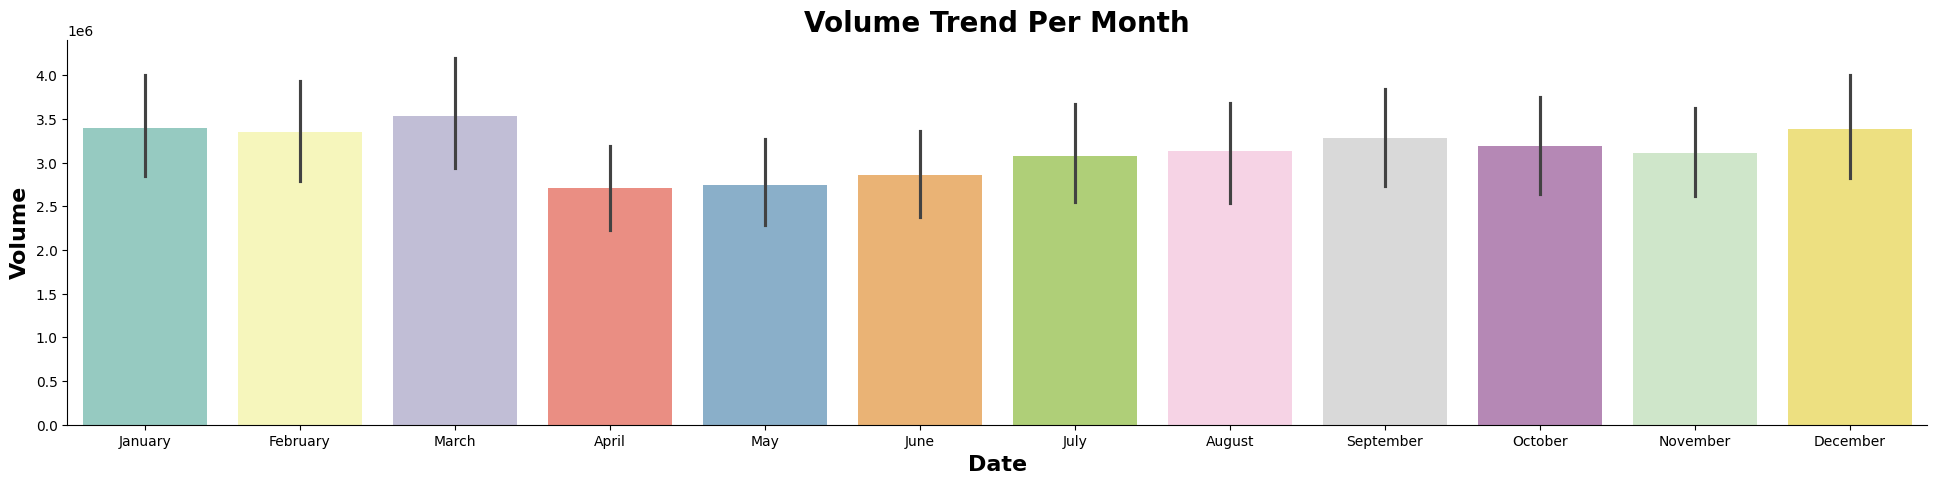

In [ ]:
plt.figure(figsize=(24,5))
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
sns.barplot(x = data['date'].dt.month_name(),y='volume',data=data,palette='Set3',order=month_order)
plt.title('Volume Trend Per Month',fontsize= 20,weight = 'bold')
plt.xlabel("Date",fontsize=16,weight = 'bold')
plt.ylabel("Volume",fontsize=16,weight = 'bold')
sns.despine()
plt.show()

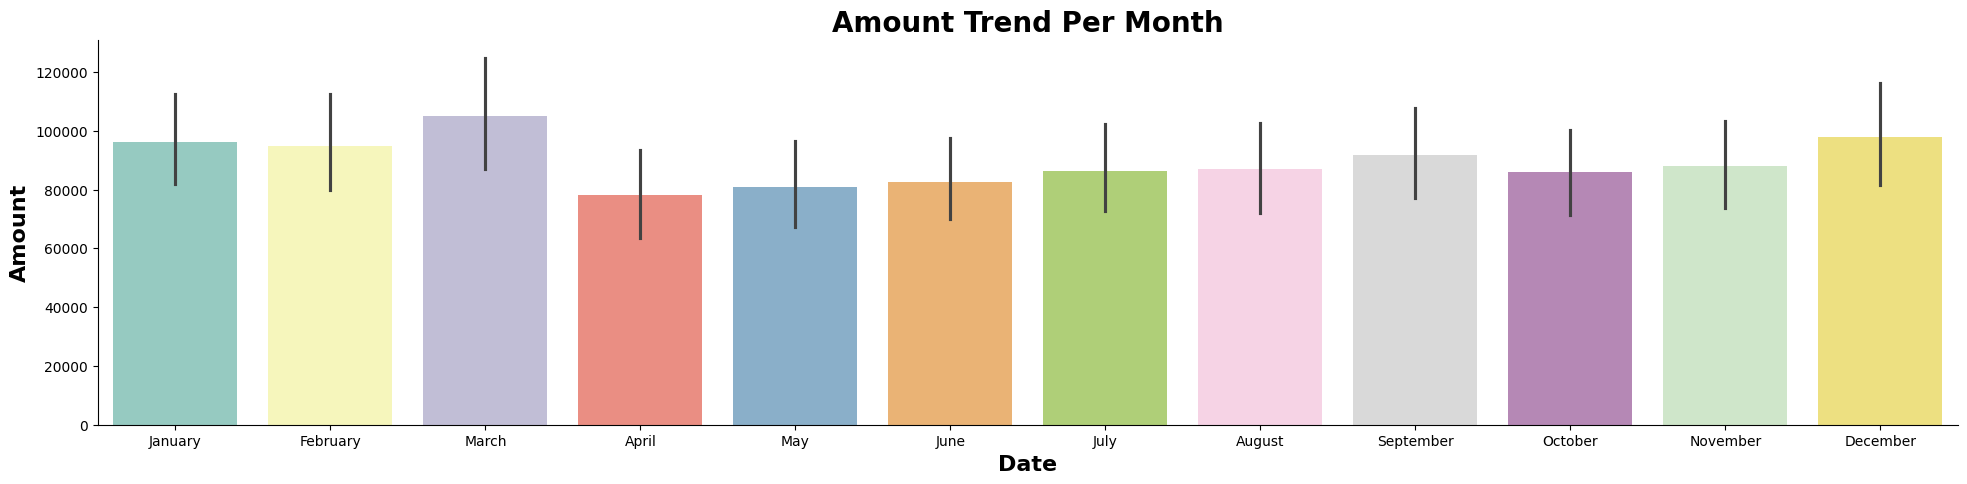

In [ ]:
plt.figure(figsize=(24,5))
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
sns.barplot(x = data['date'].dt.month_name(),y='amount',data=data,palette='Set3',order=month_order)
plt.title('Amount Trend Per Month',fontsize= 20,weight = 'bold')
plt.xlabel("Date",fontsize=16,weight = 'bold')
plt.ylabel("Amount",fontsize=16,weight = 'bold')
sns.despine()
plt.show()

`Replacing covid time with nan value`

In [32]:
covid = (data['date'] >= '2020-03-01') & (data['date'] <= '2020-06-01')
data.loc[covid, ['volume', 'amount']] = np.nan

`Filling the gaps with interpolate method (straight line filling)`

In [33]:
data = data.sort_values(['state', 'date'])
data[['volume', 'amount']] = data.groupby('state')[['volume', 'amount']].transform(lambda s: s.interpolate())

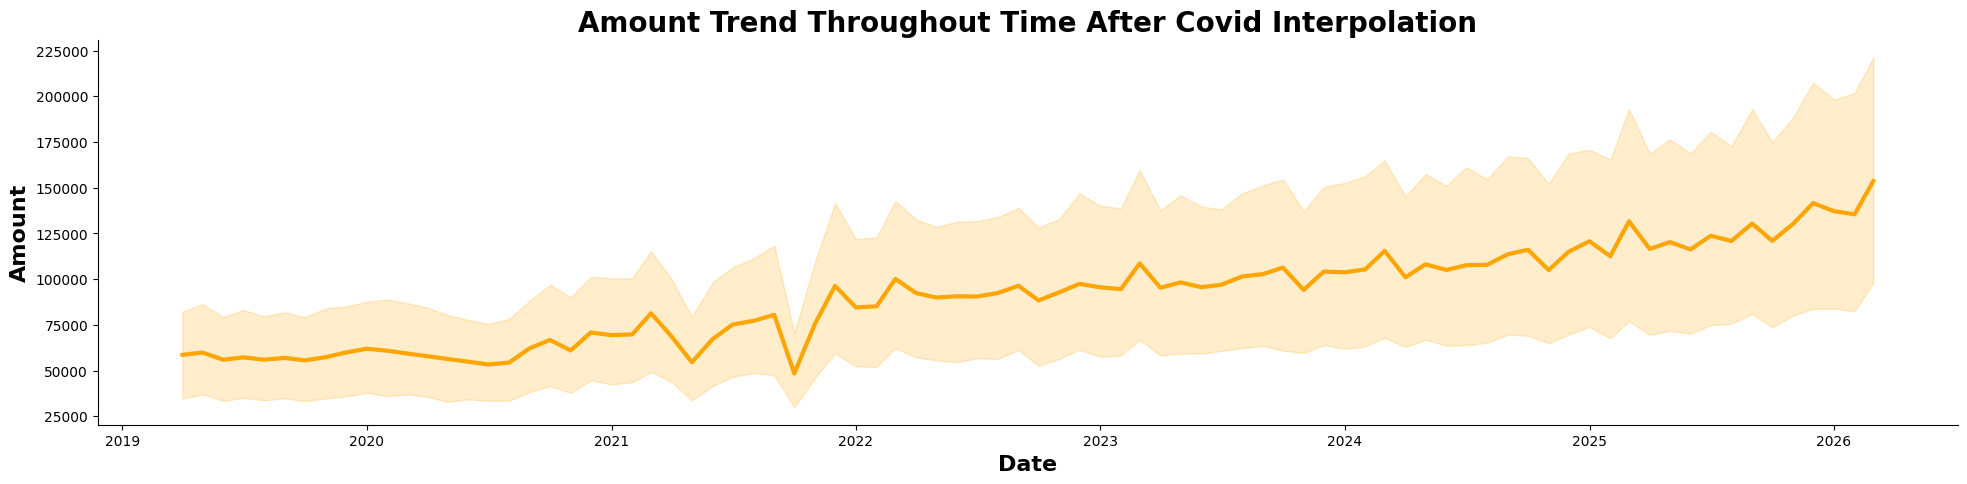

In [34]:
plt.figure(figsize=(24,5))
sns.lineplot(x = 'date',y='amount',data=data,linewidth=3,color='orange')
plt.title('Amount Trend Throughout Time After Covid Interpolation',fontsize= 20,weight = 'bold')
plt.xlabel("Date",fontsize=16,weight = 'bold')
plt.ylabel("Amount",fontsize=16,weight = 'bold')
sns.despine()
plt.show()

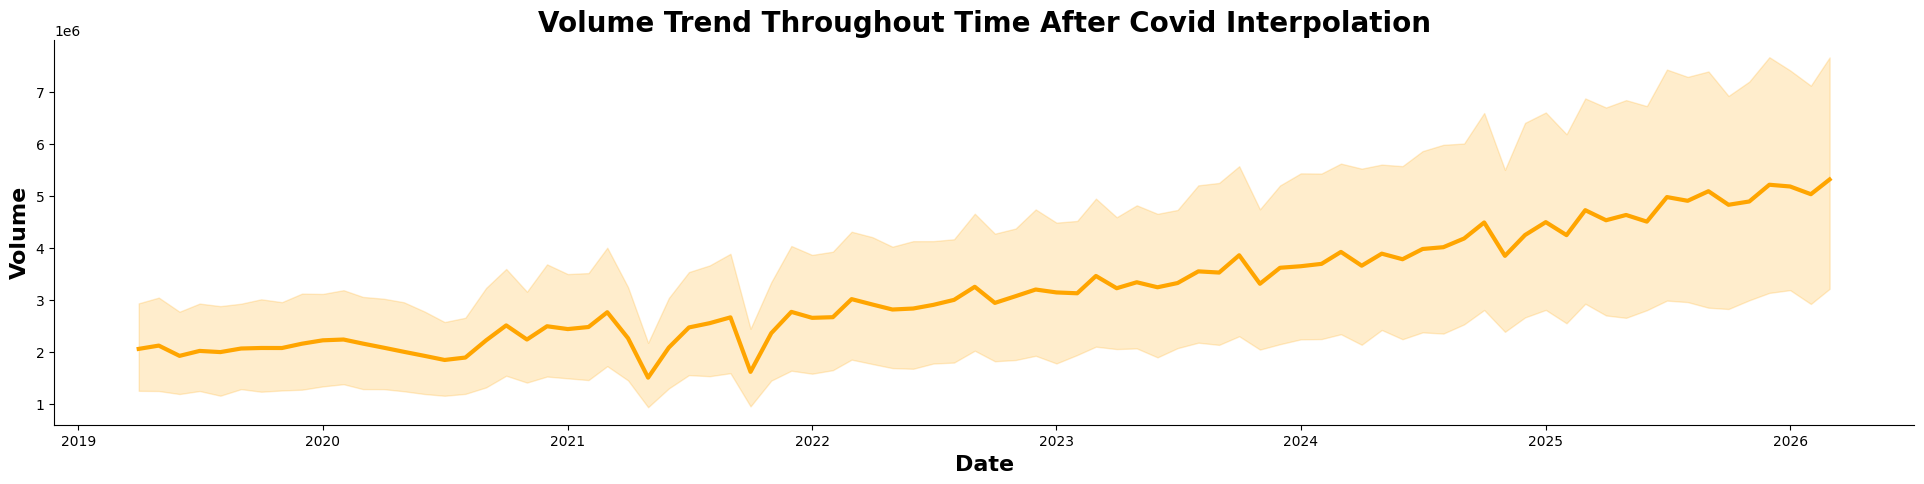

In [35]:
plt.figure(figsize=(24,5))
sns.lineplot(x = 'date',y='volume',data=data,linewidth=3,color='orange')
plt.title('Volume Trend Throughout Time After Covid Interpolation',fontsize= 20,weight = 'bold')
plt.xlabel("Date",fontsize=16,weight = 'bold')
plt.ylabel("Volume",fontsize=16,weight = 'bold')
sns.despine()
plt.show()

## **Forecasting**

`Setup`

In [ ]:
SEASON = 12
HORIZON = 24
HOLDOUT = 12
CV_H = 12
CV_WINDOWS = 5
CV_STEP = 3

`Changing variable names according to ARIMA format`

In [ ]:
def make_series(df, value_col):
    out = df[['state','date',value_col]].rename(columns={'state':'unique_id','date':'ds',value_col:'y'})
    return out.sort_values(by=['unique_id','ds']).reset_index(drop=True)


volume_data = make_series(data, 'volume')
amount_data = make_series(data, 'amount')

volume_data.head()

,unique_id,ds,y
0,andaman and nicobar,2019-04-01,8659.0
1,andaman and nicobar,2019-05-01,8731.0
2,andaman and nicobar,2019-06-01,7320.0
3,andaman and nicobar,2019-07-01,8619.0
4,andaman and nicobar,2019-08-01,9119.0


In [ ]:
amount_data.head()

,unique_id,ds,y
0,andaman and nicobar,2019-04-01,229.59
1,andaman and nicobar,2019-05-01,276.99
2,andaman and nicobar,2019-06-01,190.68
3,andaman and nicobar,2019-07-01,217.12
4,andaman and nicobar,2019-08-01,228.28


`Separating last 12 months into test set, for each state`

In [ ]:
def split_holdout(df, h=HOLDOUT):
    months_from_end = df.groupby('unique_id').cumcount(ascending=False)
    train = df[months_from_end >= h].reset_index(drop=True)
    test = df[months_from_end < h].reset_index(drop=True)
    return train, test


volume_train, volume_test = split_holdout(volume_data)
amount_train, amount_test = split_holdout(amount_data)

print(f"Train until: {amount_train['ds'].max():%b %Y}")
print(f"Test: {amount_test['ds'].min():%b %Y} to {amount_test['ds'].max():%b %Y}")

Train until: Mar 2025
Test: Apr 2025 to Mar 2026


`Checking for any lower number of rows in train data`

In [ ]:
# Enough history left for the CV windows?
shortest = amount_train.groupby('unique_id').size()
first_fit_months = shortest.min() - (CV_H + CV_STEP * (CV_WINDOWS - 1))
print(f"Shortest train series: {shortest.idxmin()} ({shortest.min()} months)")
print(f"Months available to the first CV fit: {first_fit_months}")
if first_fit_months < 2 * SEASON:
    print("Warning: first CV fit has under 2 seasons, lower CV_WINDOWS or CV_STEP")

Shortest train series: andaman and nicobar (72 months)
Months available to the first CV fit: 48


`Initializing the arima models`

In [ ]:
def get_models():
    return {
        'Naive': Naive(),
        'SeasonalNaive': SeasonalNaive(season_length=SEASON),
        'SARIMA': AutoARIMA(season_length=SEASON, alias='SARIMA'),
        'ARIMA': AutoARIMA(seasonal=False, alias='ARIMA'),
        'AutoTheta': AutoTheta(season_length=SEASON),
        'AutoETS': AutoETS(season_length=SEASON)
    }


model_names = list(get_models().keys())
model_names

['Naive', 'SeasonalNaive', 'SARIMA', 'ARIMA', 'AutoTheta', 'AutoETS']

`Cross Validation (Training Period Only)`

In [ ]:
def run_cv(train):
    sf = StatsForecast(models=list(get_models().values()), freq='MS', n_jobs=-1)
    return sf.cross_validation(df=train, h=CV_H, n_windows=CV_WINDOWS, step_size=CV_STEP)


volume_cv_result = run_cv(volume_train)
amount_cv_result = run_cv(amount_train)

`Accuracy metrics`

In [ ]:
def cv_mape(cv_result):
    # MAPE in % for every state and CV window
    parts = []
    for cutoff, fold in cv_result.groupby('cutoff'):
        ev = evaluate(fold.drop(columns='cutoff'), metrics=[mape], models=model_names)
        ev['cutoff'] = cutoff
        parts.append(ev)
    res = pd.concat(parts, ignore_index=True)
    res[model_names] = res[model_names] * 100
    return res


def summarize_cv(cv_res):
    per_state = cv_res.groupby('unique_id')[model_names].mean()
    summary = pd.DataFrame({
        'mean_mape_pct': per_state.mean(),
        'median_mape_pct': per_state.median()
    })
    return summary.round(2).sort_values('mean_mape_pct').rename_axis('model').reset_index()


volume_cv_mape = cv_mape(volume_cv_result)
amount_cv_mape = cv_mape(amount_cv_result)

In [ ]:
# Volume: MAPE (%) across states and CV windows
volume_cv_summary = summarize_cv(volume_cv_mape)
volume_cv_summary

,model,mean_mape_pct,median_mape_pct
0,SARIMA,8.43,6.03
1,AutoTheta,8.82,6.87
2,ARIMA,9.15,7.64
3,AutoETS,9.33,7.90
4,Naive,10.29,8.40
5,SeasonalNaive,12.36,11.20


In [ ]:
# Amount: MAPE (%) across states and CV windows
amount_cv_summary = summarize_cv(amount_cv_mape)
amount_cv_summary

,model,mean_mape_pct,median_mape_pct
0,SARIMA,8.09,5.73
1,AutoETS,8.64,6.48
2,SeasonalNaive,9.37,7.86
3,ARIMA,9.61,6.15
4,AutoTheta,9.73,6.23
5,Naive,11.01,8.09


In [ ]:
# Is the ranking stable from window to window? (mean MAPE % per window)
amount_cv_mape.groupby('cutoff')[model_names].mean().round(2)

,Naive,SeasonalNaive,SARIMA,ARIMA,AutoTheta,AutoETS
cutoff,,,,,,
2023-03-01,15.71,9.10,9.94,13.39,13.41,11.60
2023-06-01,10.30,8.82,8.65,8.58,8.92,8.85
2023-09-01,9.03,9.30,7.74,8.04,8.26,7.72
2023-12-01,7.59,9.36,6.50,7.36,7.58,6.93
2024-03-01,12.40,10.27,7.60,10.70,10.50,8.08


In [ ]:
# Best model = lowest mean MAPE in cross validation
best_volume = volume_cv_summary.loc[0, 'model']
best_amount = amount_cv_summary.loc[0, 'model']
print(f"Volume model: {best_volume}")
print(f"Amount model: {best_amount}")

Volume model: SARIMA
Amount model: SARIMA


`Final Forecast (Next 2 Years)`

In [ ]:
def add_fy(df):
    df = df.copy()
    start = np.where(df['ds'].dt.month >= 4, df['ds'].dt.year, df['ds'].dt.year - 1)
    df['fy'] = [f"{y}-{str(y + 1)[-2:]}" for y in start]
    return df


# Refit the chosen models on all the data
final_volume_model, final_volume_pred = fit_predict(volume_data, best_volume, HORIZON)
final_amount_model, final_amount_pred = fit_predict(amount_data, best_amount, HORIZON)

final_volume_pred = add_fy(final_volume_pred.assign(model=best_volume))
final_amount_pred = add_fy(final_amount_pred.assign(model=best_amount))

final_amount_pred.head()

,unique_id,ds,forecast,model,fy
0,andaman and nicobar,2026-04-01,762.233028,SARIMA,2026-27
1,andaman and nicobar,2026-05-01,725.771327,SARIMA,2026-27
2,andaman and nicobar,2026-06-01,782.961530,SARIMA,2026-27
3,andaman and nicobar,2026-07-01,705.240564,SARIMA,2026-27
4,andaman and nicobar,2026-08-01,746.020840,SARIMA,2026-27


In [ ]:
def plot_forecast(state=None, actual=None, forecast=None, label='Bill Volume', figsize=(24,5)):
    if state:
        actual_data = actual[actual['unique_id'] == state]
        forecast_data = forecast[forecast['unique_id'] == state]
        title = f'{label}: Actual vs Forecast — {state.title()}'
    else:
        actual_data = actual.groupby('ds')['y'].sum().reset_index()
        forecast_data = forecast.groupby('ds')['forecast'].sum().reset_index()
        title = f'Total {label}: Actual vs Forecast'

    # stitch actual and forecast so the lines connect
    last_actual = actual_data.iloc[[-1]].rename(columns={'y': 'forecast'})
    forecast_data = pd.concat([last_actual[['ds', 'forecast']], forecast_data[['ds', 'forecast']]])

    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(actual_data['ds'], actual_data['y'], label='Actual', color='#4C72B0', linewidth=2.5)
    ax.plot(forecast_data['ds'], forecast_data['forecast'], label='Forecast', linestyle='--', color='#C44E52', linewidth=2.5)

    ax.fill_between(forecast_data['ds'], forecast_data['forecast'], color='#C44E52', alpha=0.15)

    ax.axvline(actual_data['ds'].max(), color='gray', linestyle=':', linewidth=1)
    ax.text(actual_data['ds'].max(), ax.get_ylim()[1]*0.95, ' forecast starts', fontsize=9, color='gray')

    ax.legend()
    ax.set_title(title)
    ax.set_xlabel('Date')
    ax.set_ylabel(label)

    sns.despine(ax=ax)
    plt.show()

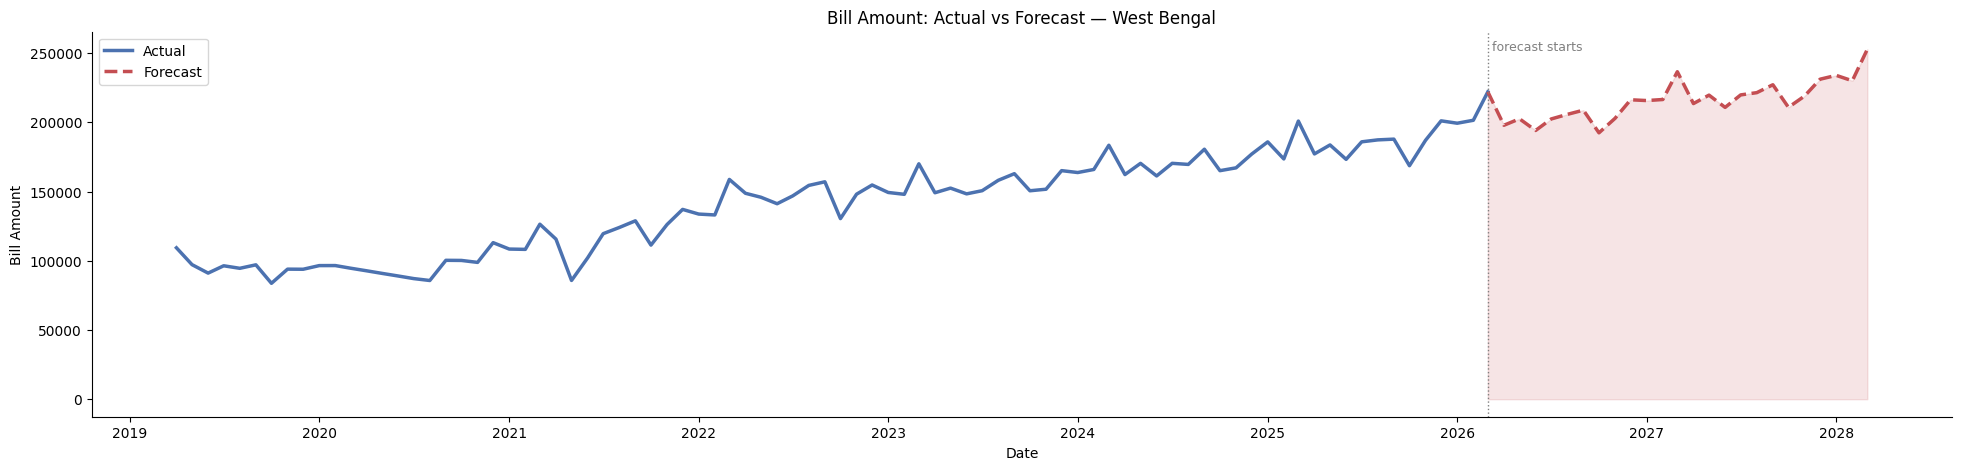

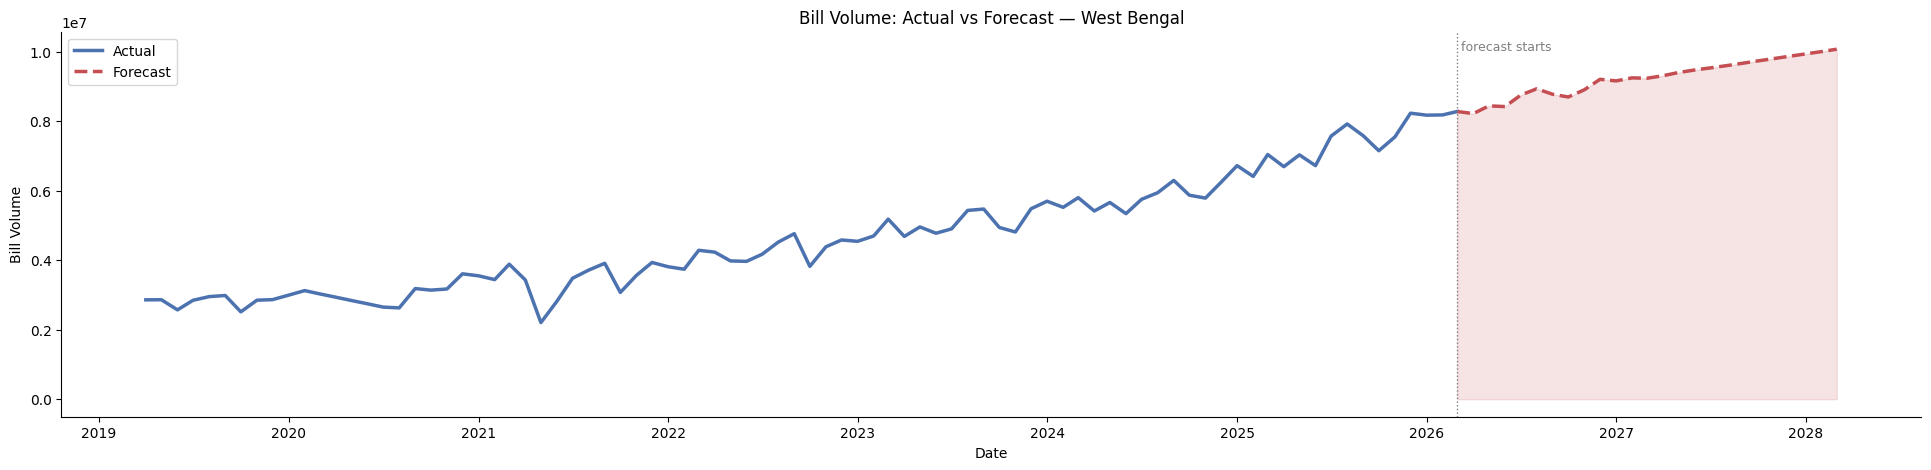

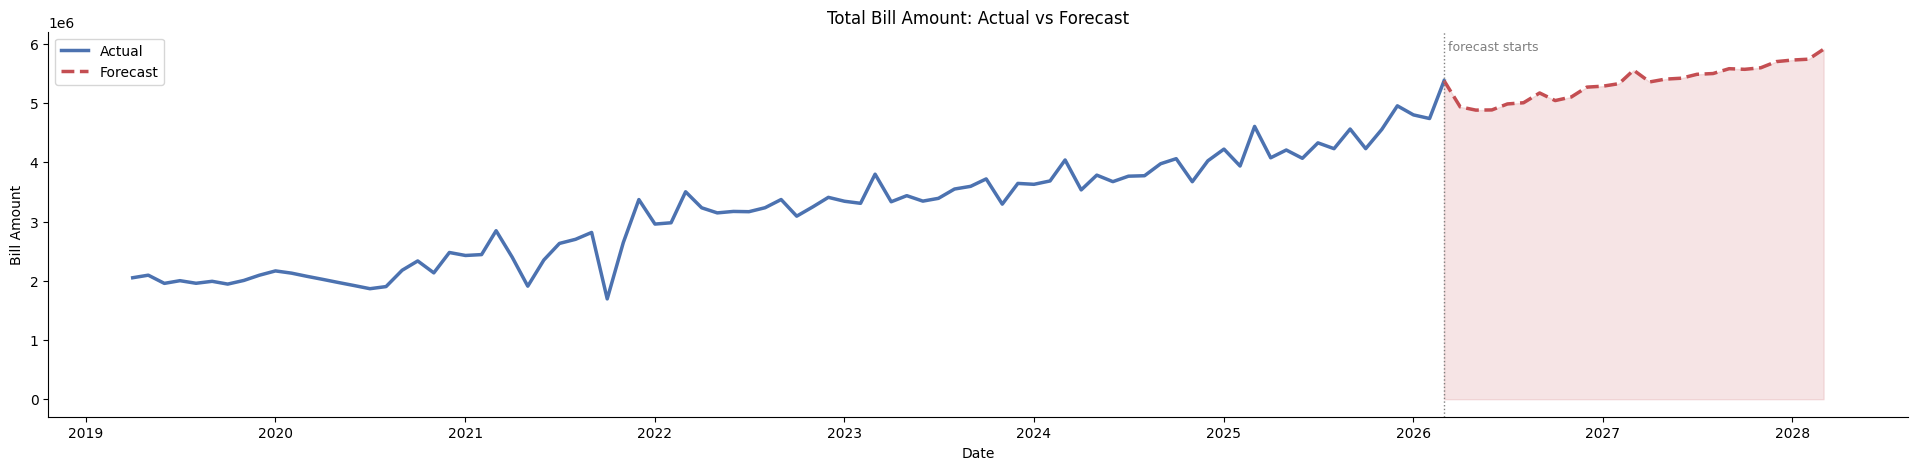

In [ ]:
plot_forecast('west bengal', amount_data, final_amount_pred, label='Bill Amount')
plot_forecast('west bengal', volume_data, final_volume_pred, label='Bill Volume')
plot_forecast(None, amount_data, final_amount_pred, label='Bill Amount')   # total of all states

`Growth Summary`

In [ ]:
def yearly_growth(actual, forecast):
    # last 12 actual months vs next 12 forecast months vs the 12 after that
    last_year = actual.sort_values(['unique_id','ds']).groupby('unique_id').tail(12).groupby('unique_id')['y'].sum()

    fc = forecast.sort_values(['unique_id','ds']).copy()
    fc['step'] = fc.groupby('unique_id').cumcount()
    next_year = fc[fc['step'] < 12].groupby('unique_id')['forecast'].sum()
    year_after = fc[(fc['step'] >= 12) & (fc['step'] < 24)].groupby('unique_id')['forecast'].sum()

    growth = pd.DataFrame({'last_year': last_year, 'next_year': next_year, 'year_after': year_after})
    growth['growth_pct'] = ((growth['next_year'] - growth['last_year']) / growth['last_year'] * 100).round(2)
    growth['growth_pct_y2'] = ((growth['year_after'] - growth['next_year']) / growth['next_year'] * 100).round(2)
    return growth


volume_growth = yearly_growth(volume_data, final_volume_pred)
amount_growth = yearly_growth(amount_data, final_amount_pred)

In [ ]:
overall_growth = pd.DataFrame({
    'volume_growth': volume_growth['growth_pct'],
    'amount_growth': amount_growth['growth_pct'],
    'volume_growth_y2': volume_growth['growth_pct_y2'],
    'amount_growth_y2': amount_growth['growth_pct_y2']
}).reset_index()

overall_growth.head()

,unique_id,volume_growth,amount_growth,volume_growth_y2,amount_growth_y2
0,andaman and nicobar,11.63,31.85,8.24,13.62
1,andhra pradesh,16.01,16.52,9.29,11.39
2,arunachal pradesh,13.94,32.45,6.82,22.68
3,assam,18.39,9.13,9.10,7.85
4,bihar,17.97,13.20,9.68,10.52


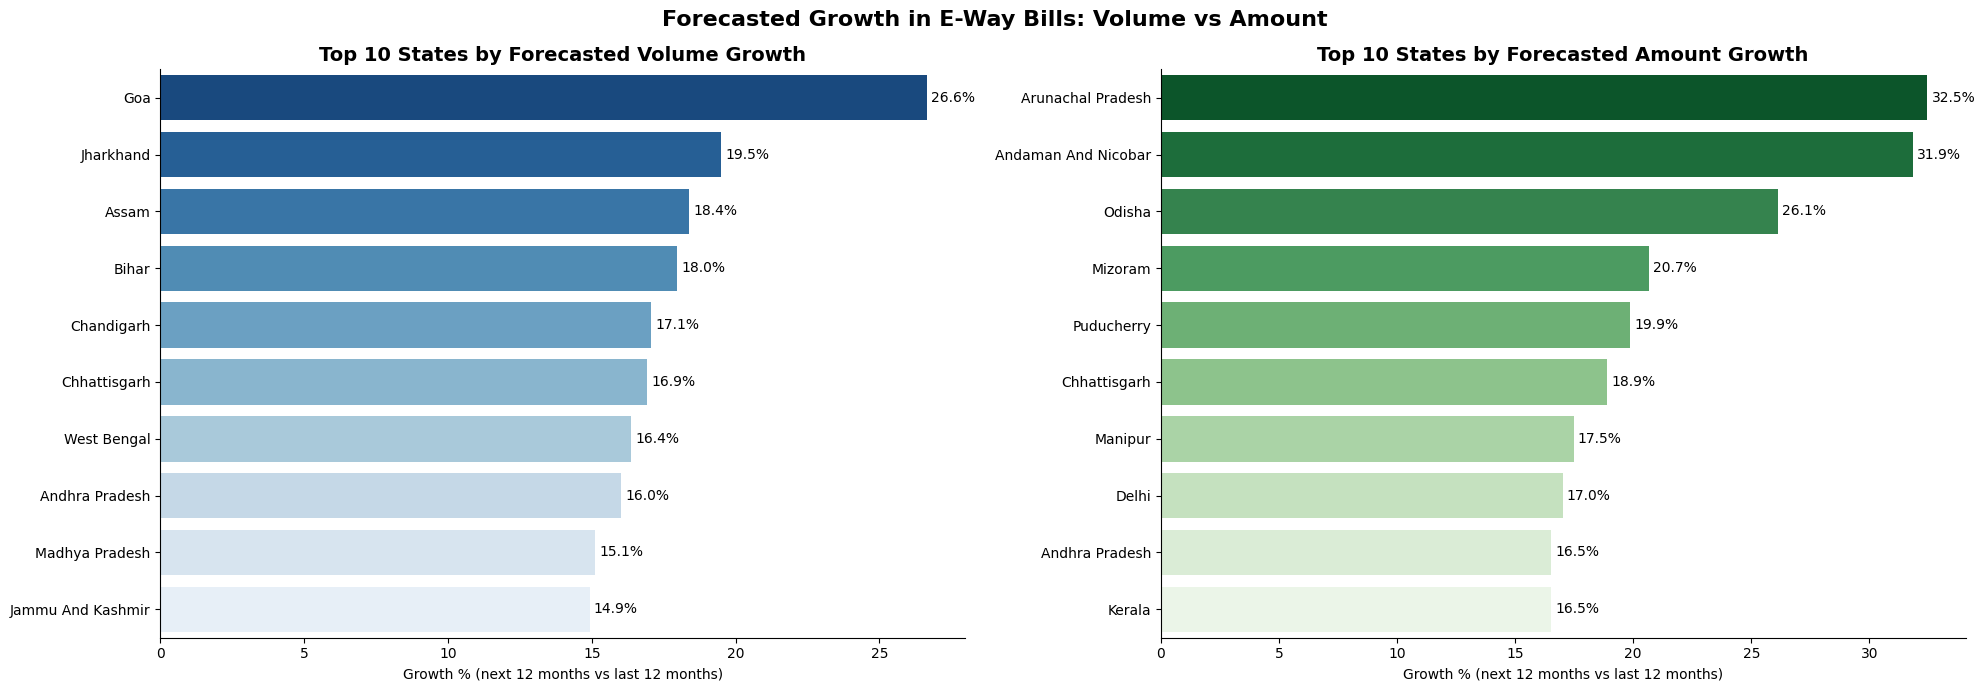

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7))

# Left chart: top 10 by volume growth
top_volume = overall_growth.nlargest(10, 'volume_growth').copy()
top_volume['unique_id'] = top_volume['unique_id'].str.title()

sns.barplot(x='volume_growth', y='unique_id', data=top_volume, palette='Blues_r', ax=ax[0])
ax[0].set_title('Top 10 States by Forecasted Volume Growth', fontsize=14, weight='bold')
ax[0].set_xlabel('Growth % (next 12 months vs last 12 months)')
ax[0].set_ylabel('')

# Right chart: top 10 by amount growth
top_amount = overall_growth.nlargest(10, 'amount_growth').copy()
top_amount['unique_id'] = top_amount['unique_id'].str.title()

sns.barplot(x='amount_growth', y='unique_id', data=top_amount, palette='Greens_r', ax=ax[1])
ax[1].set_title('Top 10 States by Forecasted Amount Growth', fontsize=14, weight='bold')
ax[1].set_xlabel('Growth % (next 12 months vs last 12 months)')
ax[1].set_ylabel('')

# Value labels on the bars and cleaner look
for a in ax:
    for container in a.containers:
        a.bar_label(container, fmt='%.1f%%', padding=3)
    sns.despine(ax=a)

fig.suptitle('Forecasted Growth in E-Way Bills: Volume vs Amount', fontsize=16, weight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"top_10_states_forecast.png", dpi=150, bbox_inches='tight')
plt.show()

`Saving outputs`

In [ ]:
# Cleaned series used for modelling
volume_data.to_csv(OUTPUT_DIR/"volume_data.csv", index=False)
amount_data.to_csv(OUTPUT_DIR/"amount_data.csv", index=False)

# Final 24 month forecasts
final_volume_pred.to_csv(OUTPUT_DIR/"volume_preds.csv", index=False)
final_amount_pred.to_csv(OUTPUT_DIR/"amount_preds.csv", index=False)

# Growth summary per state
overall_growth.to_csv(OUTPUT_DIR/"growth_summary.csv", index=False)

In [ ]:
# Model evaluation (MAPE in %)
volume_cv_summary.to_csv(OUTPUT_DIR/"volume_cv_mape.csv", index=False)
amount_cv_summary.to_csv(OUTPUT_DIR/"amount_cv_mape.csv", index=False)
volume_holdout.to_csv(OUTPUT_DIR/"volume_holdout_mape.csv", index=False)
amount_holdout.to_csv(OUTPUT_DIR/"amount_holdout_mape.csv", index=False)

In [ ]:
# Fitted models
models_dir = env_path.parent/"models"
models_dir.mkdir(parents=True, exist_ok=True)

with open(models_dir/"volume_model.pkl", "wb") as f:
    pickle.dump(final_volume_model, f)

with open(models_dir/"amount_model.pkl", "wb") as f:
    pickle.dump(final_amount_model, f)